# Cantilever Retaining Wall
**IBC 2024 1807.2.3 · ASCE 7-22 · ACI 318-19 (per foot of wall)**

Cantilever concrete retaining wall with toe, heel, and optional shear key. Computes lateral earth
pressure by Rankine (sloped backfill), Coulomb, or equivalent fluid pressure, with uniform and
strip surcharges, groundwater, stem axial load, and optional seismic increment (Mononobe-Okabe or
Seed-Whitman). Checks service stability (overturning, sliding, bearing, resultant location) and
LRFD concrete strength (stem flexure/shear by height, toe and heel flexure/shear, minimum and
temperature steel with lateral earth pressure H at 1.6).

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_ace3f170d5")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build ace3f170d5)")

structcalc 0.1.0 ready (build ace3f170d5)


In [2]:
#@title 1. Wall geometry
stem_height = 10.0  #@param {type:"number"}
retained_height = 9.0  #@param {type:"number"}
stem_thickness_top = 10.0  #@param {type:"number"}
stem_thickness_bottom = 12.0  #@param {type:"number"}
toe_length = 2.5  #@param {type:"number"}
heel_length = 4.5  #@param {type:"number"}
footing_thickness = 14.0  #@param {type:"number"}
soil_over_toe = 1.5  #@param {type:"number"}
key_depth = 0.0  #@param {type:"number"}
key_width = 12.0  #@param {type:"number"}
#@markdown Heights and toe/heel lengths in **ft** (retained height is measured from the top of the footing).
#@markdown Thicknesses and key dimensions in **in**. Front face is vertical; batter is on the back face. The key is below the stem.

In [3]:
#@title 2. Retained soil and water
method = "Rankine"  #@param ["Rankine", "Coulomb", "Equivalent fluid"]
soil_unit_weight = 120.0  #@param {type:"number"}
friction_angle = 30.0  #@param {type:"number"}
backfill_slope = 0.0  #@param {type:"number"}
wall_friction_delta = 0.0  #@param {type:"number"}
equivalent_fluid_pressure = 40.0  #@param {type:"number"}
water_height = 0.0  #@param {type:"number"}
saturated_unit_weight = 125.0  #@param {type:"number"}
#@markdown Unit weights and equivalent fluid in **pcf**; angles in **degrees** (delta is for Coulomb only).
#@markdown Water height is measured from the bottom of the footing on the retained side (0 = dry).

In [4]:
#@title 3. Surcharges, axial load, seismic
uniform_surcharge = 100.0  #@param {type:"number"}
strip_surcharge = 0.0  #@param {type:"number"}
strip_offset = 2.0  #@param {type:"number"}
strip_width = 3.0  #@param {type:"number"}
axial_D = 0.0  #@param {type:"number"}
axial_L = 0.0  #@param {type:"number"}
axial_eccentricity = 0.0  #@param {type:"number"}
seismic_method = "None"  #@param ["None", "Mononobe-Okabe", "Seed-Whitman"]
kh = 0.0  #@param {type:"number"}
include_wall_inertia = True  #@param {type:"boolean"}
#@markdown Surcharges in **psf** (treated as live load); strip offset from the back face of the stem and width in **ft**.
#@markdown Axial loads in **kip/ft**, eccentricity in **in** (+ toward the retained side).

In [5]:
#@title 4. Foundation soil and safety factors
allowable_bearing = 3.0  #@param {type:"number"}
bearing_increase_seismic = 1.0  #@param {type:"number"}
friction_coefficient = 0.45  #@param {type:"number"}
passive_pressure = 250.0  #@param {type:"number"}
passive_ignore_depth = 1.0  #@param {type:"number"}
include_soil_over_toe = True  #@param {type:"boolean"}
fs_overturning = 1.5  #@param {type:"number"}
fs_sliding = 1.5  #@param {type:"number"}
fs_seismic = 1.1  #@param {type:"number"}
#@markdown Bearing in **ksf**; passive pressure as an equivalent fluid in **pcf**; ignored depth in **ft**.

In [6]:
#@title 5. Concrete and reinforcement
fc = 3000.0  #@param {type:"number"}
fy = 60000.0  #@param {type:"number"}
stem_bar = 5  #@param [4, 5, 6, 7, 8, 9] {type:"raw"}
stem_spacing = 12.0  #@param {type:"number"}
stem_cover = 2.0  #@param {type:"number"}
horizontal_bar = 4  #@param [3, 4, 5, 6] {type:"raw"}
horizontal_spacing = 12.0  #@param {type:"number"}
toe_bar = 5  #@param [4, 5, 6, 7, 8] {type:"raw"}
toe_spacing = 12.0  #@param {type:"number"}
heel_bar = 5  #@param [4, 5, 6, 7, 8] {type:"raw"}
heel_spacing = 12.0  #@param {type:"number"}
#@markdown Stem bars are at the earth face. Horizontal bars: one layer each face. Spacings and cover in **in**.

In [7]:
#@title 6. Calculate
from structcalc.calcs import retaining_wall

out = retaining_wall.run(
    H_stem=stem_height, H_retained=retained_height, t_top=stem_thickness_top, t_bot=stem_thickness_bottom,
    toe=toe_length, heel=heel_length, h_ftg=footing_thickness, key_depth=key_depth, key_width=key_width,
    toe_cover=soil_over_toe, method=method, gamma=soil_unit_weight, phi=friction_angle, beta=backfill_slope,
    delta=wall_friction_delta, efp=equivalent_fluid_pressure, gamma_sat=saturated_unit_weight,
    h_water=water_height, surcharge=uniform_surcharge, strip_q=strip_surcharge, strip_offset=strip_offset,
    strip_width=strip_width, seismic=seismic_method, kh=kh, wall_inertia=include_wall_inertia,
    P_D=axial_D, P_L=axial_L, ecc=axial_eccentricity, qa=allowable_bearing,
    qa_increase_E=bearing_increase_seismic, mu=friction_coefficient, passive_efp=passive_pressure,
    passive_ignore=passive_ignore_depth, include_toe_soil=include_soil_over_toe,
    fs_ot=fs_overturning, fs_sl=fs_sliding, fs_seis=fs_seismic, fc=fc, fy=fy,
    stem_bar=stem_bar, stem_s=stem_spacing, stem_cover=stem_cover, horiz_bar=horizontal_bar,
    horiz_s=horizontal_spacing, toe_bar=toe_bar, toe_s=toe_spacing, heel_bar=heel_bar, heel_s=heel_spacing,
)
out["report"].show()

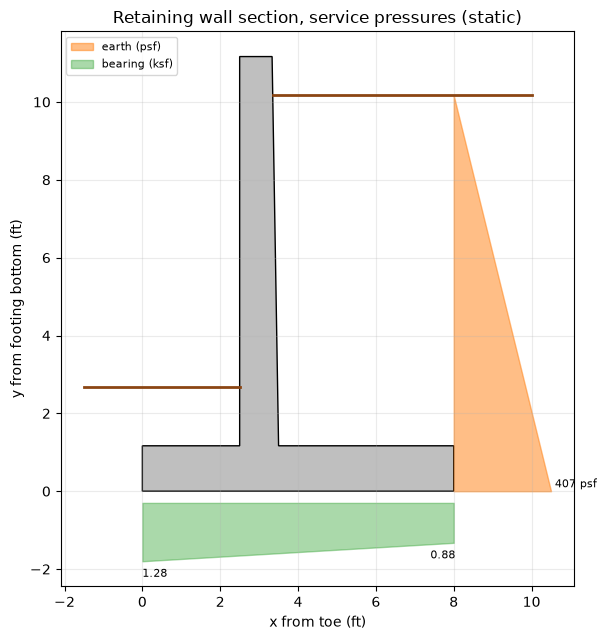

In [8]:
#@title 7. Wall section and pressures
fig = retaining_wall.plot(out)

In [9]:
#@title 8. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("retaining_wall.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass